# Predicting Arrest Outcomes in Chicago with Apache Spark

### Business Data Analytics - Final Project

**Team:** [RABIER Martin / LE CHEVALLIER Ethan / ÖHRN IBARRA Alicia]  

## Research Question

**Which characteristics of reported crime incidents in Chicago are associated with a recorded arrest, and how accurately can Apache Spark MLlib classify incidents according to this outcome?**

The project has two objectives:

1. **Descriptive analytics:** identify differences in recorded arrest rates by crime type, time, location, and domestic context.
2. **Predictive analytics:** compare machine-learning models that estimate the probability of a recorded arrest from incident characteristics.

The ultimate goal is to assess whether these analyses can inform resource planning and investigative decision-making, while recognizing that historical arrest patterns do not necessarily measure the true solvability of a crime.

## Executive Summary

### Business Context

Police departments must allocate limited investigative and operational resources across incidents that differ in nature, location, timing, and outcomes. Historical data can help identify patterns in recorded arrests and support evidence-based planning.

### Dataset and Scope

The project uses Chicago crime reports from 2022: 239,558 records and 22 columns before cleaning (239,548 records after). The analytical unit is a reported incident, not necessarily a unique criminal case.

### Analytical Approach

We clean the data, describe arrest patterns with Spark DataFrames and Spark SQL, then compare three Spark MLlib classifiers (Decision Tree, Random Forest, Gradient-Boosted Trees) with a simple baseline: the historical arrest rate of each crime type and description. Models are judged on the arrest class (precision, recall, F1) and with AUC-ROC and AUC-PR, which suit an imbalanced target. The whole pipeline (aggregations, feature encoding, parallel model training) runs in Spark and would scale unchanged to the full multi-year Chicago crime history.

### Key Findings

- Recorded arrests depend mostly on the type of offence: narcotics, weapons and trespass offences are 7.4% of incidents but 40% of arrests, while four property crimes (half of all incidents) have a 3.2% arrest rate.
- Gradient Boosting is the best of the three MLlib models (AUC-ROC 0.844; precision 0.43 and recall 0.65 on the arrest class).
- A simple lookup of historical arrest rates by crime type and description does better (AUC-ROC 0.885): with these variables, machine learning adds no value.
- Performance is much lower on victim-reported crimes (AUC-ROC 0.76 for the best model).

### Intended Business Value

The project evaluates whether incident characteristics contain useful predictive information and whether the resulting analysis could support human-led resource planning. It does not attempt to automate arrest decisions.

In [0]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.functions import col, when, sum
from pyspark.sql.types import StringType

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler
)
from pyspark.ml.classification import (
    DecisionTreeClassifier,
    RandomForestClassifier,
    GBTClassifier
)
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator
)
from pyspark.ml.stat import ChiSquareTest

spark = SparkSession.builder \
    .appName("ChicagoCrimeArrestPrediction") \
    .getOrCreate()

sns.set_theme(style="whitegrid")

## 1. Data Source and Loading

The dataset supplied with this project contains Chicago crime reports for 2022. Each row represents a reported incident and includes categorical crime descriptions, timestamps, geographic identifiers, and a recorded arrest indicator.

The original CSV contains 239,558 records and 22 columns. Currently, the data is loaded from a table in the default Databricks workspace, but it can alternatively be loaded directly from the project directory to avoid dependencies on workspace-specific permissions.


In [0]:
initial_df = spark.table("crime_prediction_in_chicago")
# initial_df = spark.read.format("csv").option("header", "true").option("inferSchema", "true").load("dbfs:/path/to/your/project/directory/Crime Prediction in Chicago_Dataset.csv")
initial_df.dtypes

[('ID', 'bigint'),
 ('Case Number', 'string'),
 ('Date', 'string'),
 ('Block', 'string'),
 ('IUCR', 'string'),
 ('Primary Type', 'string'),
 ('Description', 'string'),
 ('Location Description', 'string'),
 ('Arrest', 'boolean'),
 ('Domestic', 'boolean'),
 ('Beat', 'bigint'),
 ('District', 'bigint'),
 ('Ward', 'bigint'),
 ('Community Area', 'bigint'),
 ('FBI Code', 'string'),
 ('X Coordinate', 'bigint'),
 ('Y Coordinate', 'bigint'),
 ('Year', 'bigint'),
 ('Updated On', 'string'),
 ('Latitude', 'double'),
 ('Longitude', 'double'),
 ('Location', 'string')]

## 2. Data Quality Assessment and Preprocessing

In order to consider the dataset useable we want to clean the dataset.

Rather than cleaning this data right away, we should investigate these leads first, as they raise some important questions about the following things:
- selecting a single ID (ID vs. case number?)
-  formatting dates, dropping the year column since the dataset only covers 2022 and the update date.
-  handling coordinates (block, latitude/longitude, coordinate X/Y)


In [0]:
ID_amount = initial_df.select("ID").distinct().count()
CASE_amount = initial_df.select("Case Number").distinct().count()
print(f"""{initial_df.count()} lines, {ID_amount} different ID, {CASE_amount} different case ID""")

239558 lines, 239558 different ID, 239511 different case ID


**Incident IDs and Case Numbers**

There are 239,558 distinct IDs but only 239,511 distinct case numbers, so a few cases contain several incidents. Both columns are close to one unique value per row: they identify incidents but carry no predictive meaning, and encoding them would be very costly. We therefore drop the case number and keep the ID only to trace incidents, not as a model feature.

In [0]:
different_year = initial_df.select("Year").distinct().count()
different_year

1

In [0]:
work_df = initial_df.drop("Year","Updated On","Case Number")
work_df.dtypes

[('ID', 'bigint'),
 ('Date', 'string'),
 ('Block', 'string'),
 ('IUCR', 'string'),
 ('Primary Type', 'string'),
 ('Description', 'string'),
 ('Location Description', 'string'),
 ('Arrest', 'boolean'),
 ('Domestic', 'boolean'),
 ('Beat', 'bigint'),
 ('District', 'bigint'),
 ('Ward', 'bigint'),
 ('Community Area', 'bigint'),
 ('FBI Code', 'string'),
 ('X Coordinate', 'bigint'),
 ('Y Coordinate', 'bigint'),
 ('Latitude', 'double'),
 ('Longitude', 'double'),
 ('Location', 'string')]

In [0]:
#observing date format
work_df.select("date").limit(1).display()

date
1/14/2022 15:55


We see here the format is Month/Day/Year Time

In [0]:
work_df = work_df.withColumn("date", F.to_timestamp(F.col("date"), "M/d/yyyy H:mm"))
work_df.printSchema()

root
 |-- ID: long (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- Block: string (nullable = true)
 |-- IUCR: string (nullable = true)
 |-- Primary Type: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Location Description: string (nullable = true)
 |-- Arrest: boolean (nullable = true)
 |-- Domestic: boolean (nullable = true)
 |-- Beat: long (nullable = true)
 |-- District: long (nullable = true)
 |-- Ward: long (nullable = true)
 |-- Community Area: long (nullable = true)
 |-- FBI Code: string (nullable = true)
 |-- X Coordinate: long (nullable = true)
 |-- Y Coordinate: long (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Location: string (nullable = true)



In [0]:
loc_columns = ["Block", "X Coordinate", "Y Coordinate", "Latitude", "Longitude", "Location"]
null_checks = [sum(when(col(c).isNull(), 1).otherwise(0)).alias(c) for c in loc_columns]
work_df.select(null_checks).display()

Block,X Coordinate,Y Coordinate,Latitude,Longitude,Location
0,4667,4667,4667,4667,4667


Exact coordinates (X/Y, latitude/longitude, location) are missing for **4,667 rows (1.9%)**. Using them would force either imputation or row loss, and a street-level view is enough for this question. We keep **Block** (0 missing), remove the house number so that incidents on the same street are comparable (about 2,460 distinct streets remain), and drop the coordinate columns.

In [0]:
work_df = work_df.withColumn("Block", F.regexp_replace(F.col("Block"), "^\\S+\\s+", ""))
display(work_df)
work_df.printSchema()

ID,date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Latitude,Longitude,Location
12592454,2022-01-14T15:55:00.000Z,S MORGAN ST,2826,OTHER OFFENSE,HARASSMENT BY ELECTRONIC MEANS,RESIDENCE,false,true,724,7,16,68,26,1170805,1860170,41.77178244,-87.64943693,"(41.771782439, -87.649436929)"
12785595,2022-08-05T21:00:00.000Z,S UNIVERSITY AVE,1544,SEX OFFENSE,SEXUAL EXPLOITATION OF A CHILD,APARTMENT,true,false,324,3,5,69,17,1185135,1857211,41.76333797,-87.59700113,"(41.763337967, -87.597001131)"
12808281,2022-08-14T14:00:00.000Z,W ARDMORE AVE,1562,SEX OFFENSE,AGGRAVATED CRIMINAL SEXUAL ABUSE,RESIDENCE,false,false,1621,16,39,11,17,1138383,1937953,41.98587528,-87.76640386,"(41.985875279, -87.766403857)"
12888104,2022-11-10T03:47:00.000Z,S MAY ST,1477,WEAPONS VIOLATION,RECKLESS FIREARM DISCHARGE,STREET,false,false,733,7,17,68,15,1169903,1856822,41.76261474,-87.65284046,"(41.76261474, -87.652840463)"
13209277,2022-08-15T09:00:00.000Z,W JACKSON BLVD,810,THEFT,OVER $500,COMMERCIAL / BUSINESS OFFICE,false,false,113,1,4,32,6,null,null,null,null,null
12622465,2022-02-19T10:36:00.000Z,N FRANCISCO AVE,486,BATTERY,DOMESTIC BATTERY SIMPLE,HOSPITAL BUILDING / GROUNDS,true,true,1211,12,26,24,08B,1156861,1906972,41.90050559,-87.69928504,"(41.900505589, -87.699285044)"
12640859,2022-03-13T05:15:00.000Z,W PRATT BLVD,486,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,true,true,2431,24,49,1,08B,1166646,1945317,42.00552183,-87.66224145,"(42.00552183, -87.662241448)"
12667337,2022-04-10T21:38:00.000Z,N CHERRY AVE,4387,OTHER OFFENSE,VIOLATE ORDER OF PROTECTION,WAREHOUSE,true,true,1822,18,27,8,26,1169620,1907431,41.90149679,-87.65240739,"(41.901496787, -87.652407386)"
12671049,2022-04-14T22:10:00.000Z,E OHIO ST,486,BATTERY,DOMESTIC BATTERY SIMPLE,VEHICLE - COMMERCIAL,true,true,1834,18,2,8,08B,1178915,1904276,41.8926318,-87.61836282,"(41.892631803, -87.618362824)"
12678035,2022-04-22T23:30:00.000Z,N BROADWAY,810,THEFT,OVER $500,APARTMENT,true,true,1914,19,46,3,6,1168614,1929562,41.96224718,-87.6554598,"(41.962247182, -87.6554598)"


root
 |-- ID: long (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- Block: string (nullable = true)
 |-- IUCR: string (nullable = true)
 |-- Primary Type: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Location Description: string (nullable = true)
 |-- Arrest: boolean (nullable = true)
 |-- Domestic: boolean (nullable = true)
 |-- Beat: long (nullable = true)
 |-- District: long (nullable = true)
 |-- Ward: long (nullable = true)
 |-- Community Area: long (nullable = true)
 |-- FBI Code: string (nullable = true)
 |-- X Coordinate: long (nullable = true)
 |-- Y Coordinate: long (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Location: string (nullable = true)



In [0]:
work_df = work_df.drop( "X Coordinate", "Y Coordinate", "Latitude", "Longitude", "Location")

### Missing Values and Data Quality

In [0]:
null_checks = [sum(when(col(c).isNull(), 1).otherwise(0)).alias(c) for c in work_df.columns]
work_df.select(null_checks).display()

ID,date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code
0,0,0,0,0,0,965,0,0,0,0,10,0,0


Two columns have missing values: **Ward** (10 rows, 0.004%) and **Location Description** (965 rows, 0.4%). We drop the 10 rows without a Ward.

In [0]:
work_df = work_df.dropna(subset=["Ward"])


In [0]:
work_df.groupBy("Location Description").count().orderBy(col("count").desc()).head(10)

[Row(Location Description='STREET', count=67637),
 Row(Location Description='APARTMENT', count=45746),
 Row(Location Description='RESIDENCE', count=30603),
 Row(Location Description='SIDEWALK', count=12059),
 Row(Location Description='PARKING LOT / GARAGE (NON RESIDENTIAL)', count=9333),
 Row(Location Description='SMALL RETAIL STORE', count=7261),
 Row(Location Description='ALLEY', count=5018),
 Row(Location Description='RESTAURANT', count=4867),
 Row(Location Description='OTHER (SPECIFY)', count=3629),
 Row(Location Description='COMMERCIAL / BUSINESS OFFICE', count=3599)]

We fill the missing locations with the most frequent value (`STREET`) which is acceptable given how few rows are concerned.

In [0]:
mode_value = work_df.select(F.mode("Location Description")).first()[0]
work_df = work_df.na.fill({"Location Description": mode_value})
null_checks = [sum(when(col(c).isNull(), 1).otherwise(0)).alias(c) for c in work_df.columns]
work_df.select(null_checks).display()

ID,date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code
0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 3. Exploratory Data Analysis (EDA)

The dataset no longer has missing values, so we can explore it in four steps:

- **3.1 Univariate analysis:** the most frequent crime types, descriptions and locations, and the distribution of the target (`Arrest`).
- **3.2 Bivariate analysis:** arrest rates by crime type, time, district, location and domestic context.
- **3.3 Spark SQL:** the same aggregations written in SQL.
- **3.4 Proactive vs reactive offences:** a distinction that matters for the modeling part.

Counts and arrest rates must be read together: a category can be frequent with a low arrest rate, and a high rate on few incidents can be unreliable.

### 3.1 Univariate analysis

In [0]:
df = work_df
df.printSchema()

root
 |-- ID: long (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- Block: string (nullable = true)
 |-- IUCR: string (nullable = true)
 |-- Primary Type: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Location Description: string (nullable = false)
 |-- Arrest: boolean (nullable = true)
 |-- Domestic: boolean (nullable = true)
 |-- Beat: long (nullable = true)
 |-- District: long (nullable = true)
 |-- Ward: long (nullable = true)
 |-- Community Area: long (nullable = true)
 |-- FBI Code: string (nullable = true)



/home/spark-409d4cc2-744a-4f00-91e3-30/.ipykernel/66/command-8045852107490024-2083831961:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=IUCR,x="count",y="IUCR",palette="viridis")


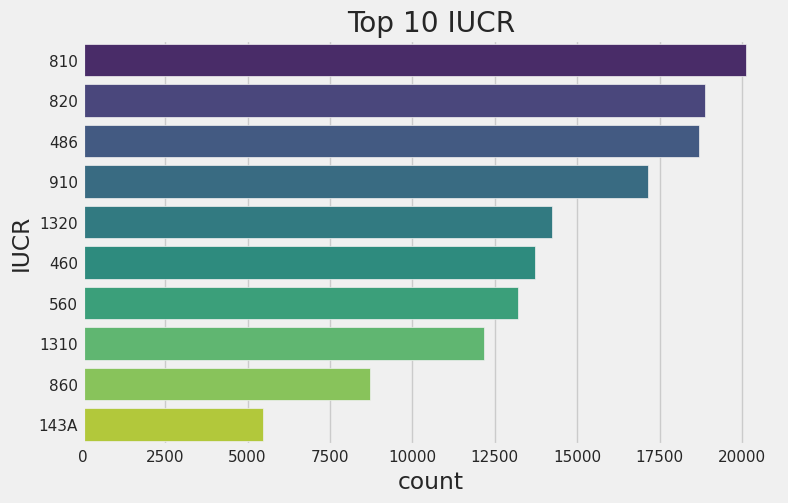

In [0]:
IUCR =df.groupBy("IUCR").count().orderBy(col("count").desc()).limit(10) # over 300 total
IUCR = IUCR.toPandas()
plt.style.use("fivethirtyeight")
plt.figure(figsize=(8,5))
sns.barplot(data=IUCR,x="count",y="IUCR",palette="viridis")
plt.title("Top 10 IUCR")
plt.ylabel("IUCR")
plt.xlabel("count")
plt.show()

/home/spark-409d4cc2-744a-4f00-91e3-30/.ipykernel/66/command-7612676288223633-659923350:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=Description,x="count",y="Description",palette="viridis")


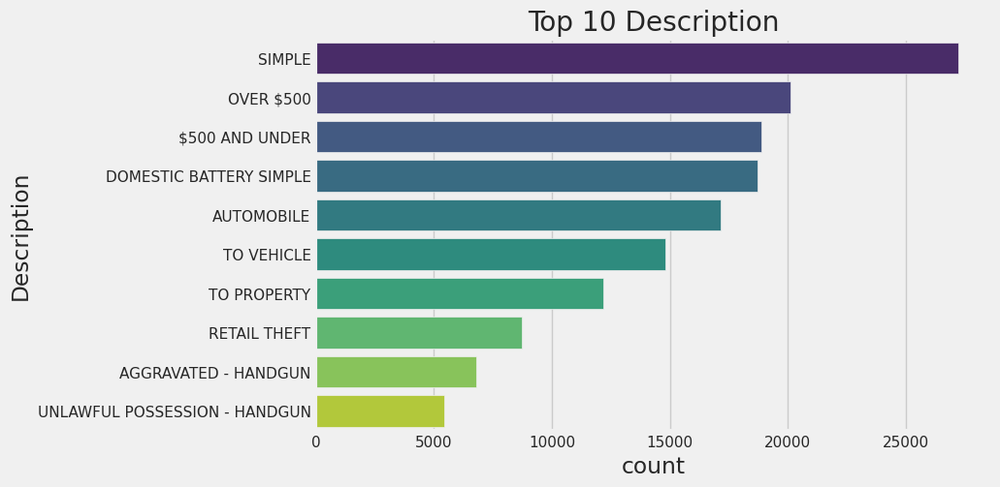

In [0]:
Description = df.groupBy("Description").count().orderBy(col("count").desc()).limit(10) #283 rows total
Description =Description.toPandas()
plt.style.use("fivethirtyeight")
plt.figure(figsize=(8,5))
sns.barplot(data=Description,x="count",y="Description",palette="viridis")
plt.title("Top 10 Description")
plt.ylabel("Description")
plt.xlabel("count")
plt.show()


Descriptions are spread over 285 distinct values with no dominant one. IUCR is the police code for the same information, so it is not studied separately.

/home/spark-409d4cc2-744a-4f00-91e3-30/.ipykernel/66/command-7612676288223630-616554059:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=PT,x="count",y="Primary Type",palette="viridis")


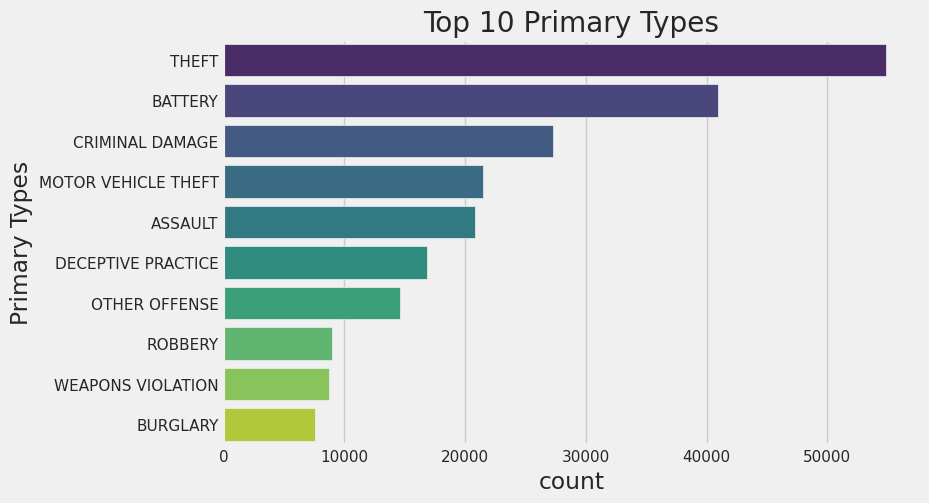

In [0]:
PT = df.groupBy("Primary Type").count().orderBy(col("count").desc()).limit(10) # 31 total
PT =PT.toPandas()
plt.style.use("fivethirtyeight")
plt.figure(figsize=(8,5))
sns.barplot(data=PT,x="count",y="Primary Type",palette="viridis")
plt.title("Top 10 Primary Types")
plt.ylabel("Primary Types")
plt.xlabel("count")
plt.show()

Primary Type has 31 categories and is more concentrated: Theft (54,884), Battery (40,945) and Criminal Damage (27,248) make up 51.4% of incidents. It is the most informative variable of the dataset, and this imbalance is acceptable given the size of the data.

/home/spark-409d4cc2-744a-4f00-91e3-30/.ipykernel/66/command-7612676288223642-1635444774:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=FBI,x="count",y="FBI Code",palette="viridis")


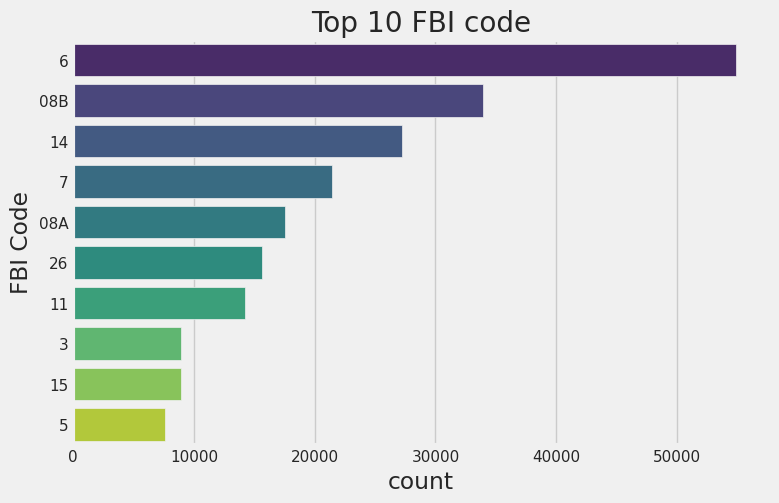

In [0]:
FBI = df.groupBy("FBI Code").count().orderBy(col("count").desc()).limit(10) 
FBI = FBI.toPandas()
plt.style.use("fivethirtyeight")
plt.figure(figsize=(8,5))
sns.barplot(data=FBI,x="count",y="FBI Code",palette="viridis")
plt.title("Top 10 FBI code")
plt.ylabel("FBI Code")
plt.xlabel("count")
plt.show()


Once again here we have the visual validation that the FBI Code is used to categorize internally the crime description.

/home/spark-409d4cc2-744a-4f00-91e3-30/.ipykernel/66/command-7612676288223640-373567320:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=LDescription,x="count",y="Location Description",palette="viridis")


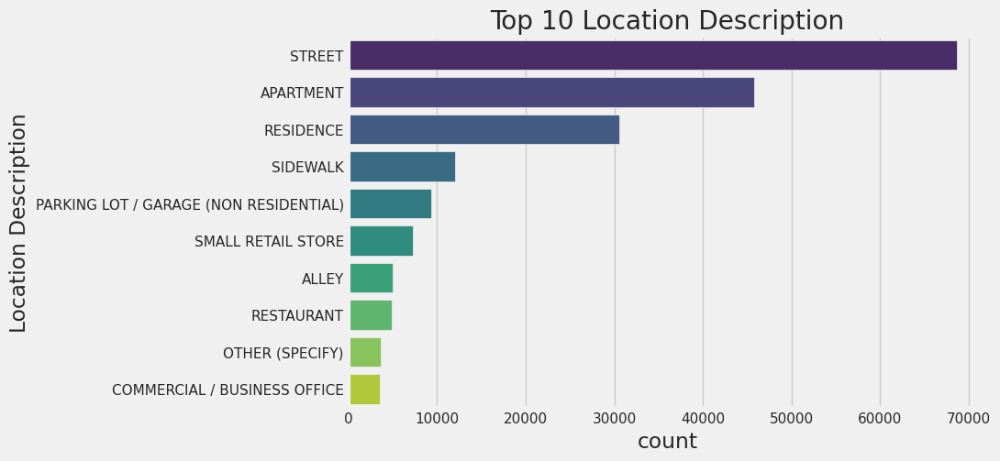

In [0]:
LDescription = df.groupBy("Location Description").count().orderBy(col("count").desc()).limit(10) #283 rows total
LDescription = LDescription.toPandas()
plt.style.use("fivethirtyeight")
plt.figure(figsize=(8,5))
sns.barplot(data=LDescription,x="count",y="Location Description",palette="viridis")
plt.title("Top 10 Location Description")
plt.ylabel("Location Description")
plt.xlabel("count")
plt.show()


Three location types account for about 60% of incidents: street (28.6%), apartment (19.1%) and residence (12.8%).

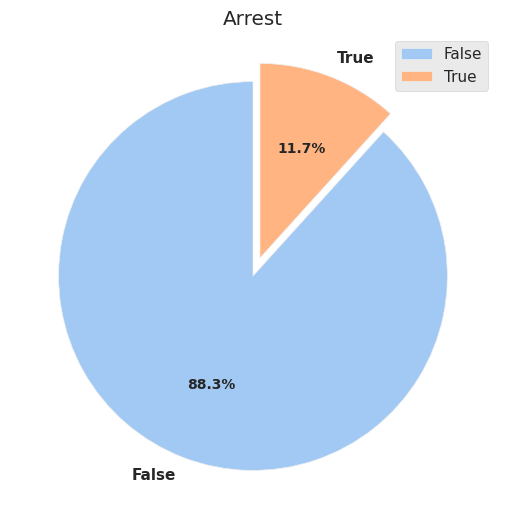

In [0]:
Arrest = df.groupBy("Arrest").count().orderBy(col("count").desc()).toPandas()

plt.style.use("ggplot")
plt.figure(figsize=(6, 6))
plt.pie(Arrest["count"], labels=Arrest["Arrest"], autopct='%1.1f%%', startangle=90,textprops={"fontweight":"black"},explode=[0, 0.1],colors=sns.color_palette("pastel"))
plt.title("Arrest")
plt.legend()
plt.show()


Only **11.7%** of incidents lead to an arrest (28,050 out of 239,548), against **88.3%** without one. A model trained naively on this distribution would reach a deceptively high accuracy (about 88%) by always predicting "no arrest", while detecting none of the arrests we want to identify. Since `Arrest` is our target, we keep it, address the imbalance with class weighting (see the modeling section) and evaluate the models mainly on the arrest class (precision, recall, F1) and with AUC-ROC and AUC-PR rather than on accuracy.

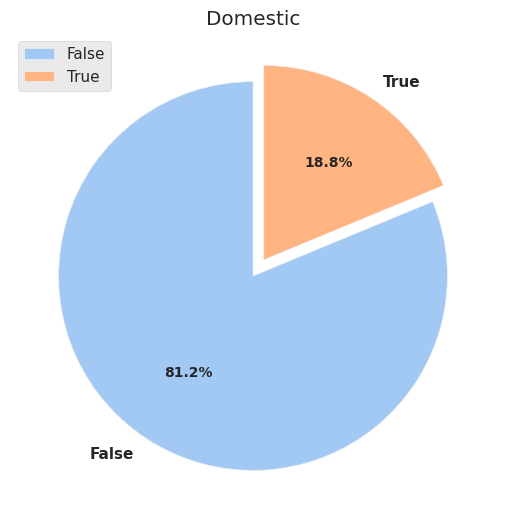

In [0]:
Domestic = df.groupBy("Domestic").count().orderBy(col("count").desc()).toPandas()

plt.style.use("ggplot")
plt.figure(figsize=(6, 6))
plt.pie(Domestic["count"], labels=Domestic["Domestic"], autopct='%1.1f%%', startangle=90,textprops={"fontweight":"black"},explode=[0, 0.1],colors=sns.color_palette("pastel"))
plt.title("Domestic")
plt.legend()
plt.show()


Domestic incidents are **18.8%** of the data (**44,916 rows**). The Domestic variable is not the prediction target. Its distribution describes how many incidents are flagged as domestic-related in the dataset.

Its usefulness should be assessed by comparing arrest rates between domestic and non-domestic incidents, while accounting for the number of observations in each group. The class distribution alone does not establish whether Domestic is a useful predictive feature.

### 3.2 Bivariate analysis: arrest rate by crime type, time and place

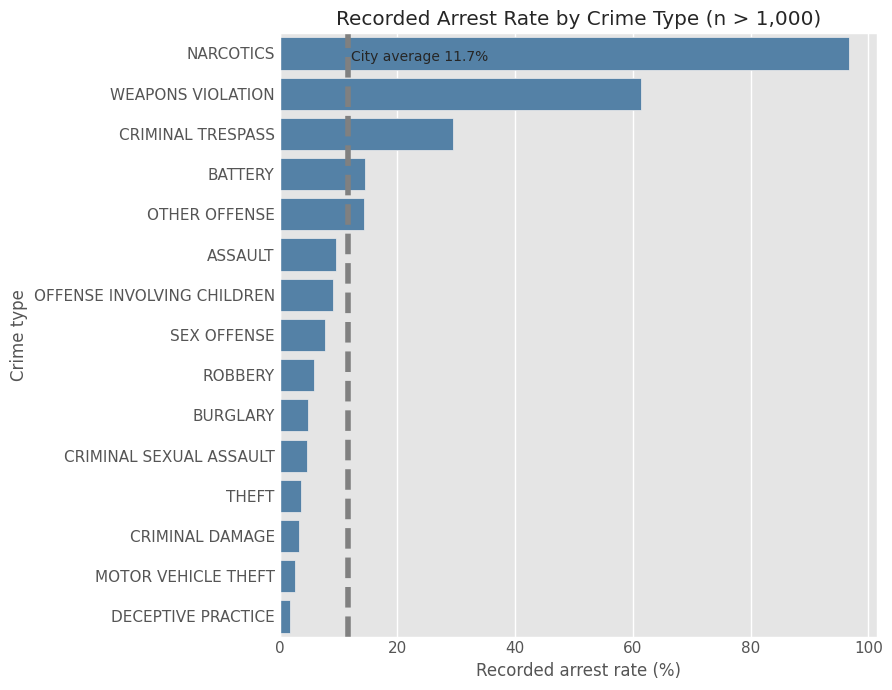

Primary Type,n,arrests,arrest_rate_pct
NARCOTICS,4755,4599,96.7
WEAPONS VIOLATION,8779,5392,61.4
CRIMINAL TRESPASS,4223,1246,29.5
BATTERY,40945,5951,14.5
OTHER OFFENSE,14609,2092,14.3
ASSAULT,20808,2007,9.6
OFFENSE INVOLVING CHILDREN,1870,168,9.0
SEX OFFENSE,1216,95,7.8
ROBBERY,8963,531,5.9
BURGLARY,7593,366,4.8


In [0]:
by_type = (
    df.groupBy("Primary Type")
    .agg(
        F.count("*").alias("n"),
        F.sum(F.col("Arrest").cast("int")).alias("arrests"),
        F.round(
            100 * F.avg(F.col("Arrest").cast("int")), 1
        ).alias("arrest_rate_pct")
    )
    .filter(F.col("n") > 1000)
    .orderBy(F.desc("arrest_rate_pct"))
)

by_type_pd = by_type.toPandas()

plt.figure(figsize=(9, 7))
sns.barplot(
    data=by_type_pd,
    x="arrest_rate_pct",
    y="Primary Type",
    color="steelblue"
)
plt.xlabel("Recorded arrest rate (%)")
plt.ylabel("Crime type")
plt.title("Recorded Arrest Rate by Crime Type (n > 1,000)")
plt.tight_layout()
city_rate = 100 * df.agg(F.avg(F.col("Arrest").cast("int"))).first()[0]
plt.axvline(city_rate, ls="--", color="grey"); plt.text(city_rate + 0.5, 0.2, f"City average {city_rate:.1f}%")
plt.show()

display(by_type_pd)

**Crime type is by far the strongest driver of recorded arrests.** 

Narcotics (96.7%; n = 4,755), Weapons Violation (61.4%; n = 8,779) and Criminal Trespass (29.5%; n = 4,223) are the only types well above the city average of 11.7%. At the other end, the four property crimes (Theft, Motor Vehicle Theft, Criminal Damage and Deceptive Practice) represent **50.3% of all incidents (120,447) but only 3,802 arrests (3.2%)**. The largest category, Theft, has 54,884 incidents and a 3.7% arrest rate. This is the main workload-versus-outcome gap in the data.

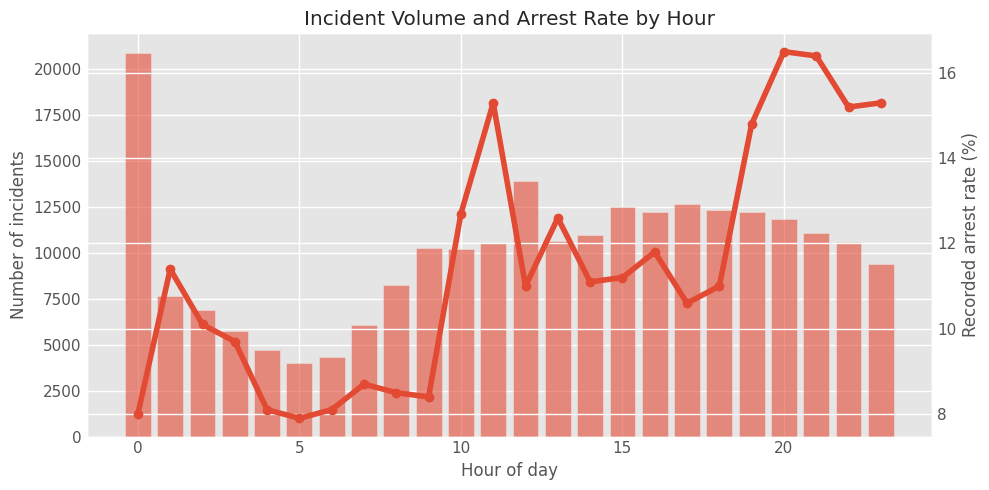

In [0]:
temporal_df = (
    df.withColumn("hour", F.hour("date"))
      .withColumn("day_of_week", F.dayofweek("date"))
      .withColumn("month", F.month("date"))
)

by_hour = (
    temporal_df.groupBy("hour")
    .agg(
        F.count("*").alias("n"),
        F.round(
            100 * F.avg(F.col("Arrest").cast("int")), 1
        ).alias("arrest_rate_pct")
    )
    .orderBy("hour")
    .toPandas()
)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(by_hour["hour"], by_hour["n"], alpha=0.6)
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Number of incidents")

ax2 = ax1.twinx()
ax2.plot(
    by_hour["hour"],
    by_hour["arrest_rate_pct"],
    marker="o"
)
ax2.set_ylabel("Recorded arrest rate (%)")

plt.title("Incident Volume and Arrest Rate by Hour")
fig.tight_layout()
plt.show()

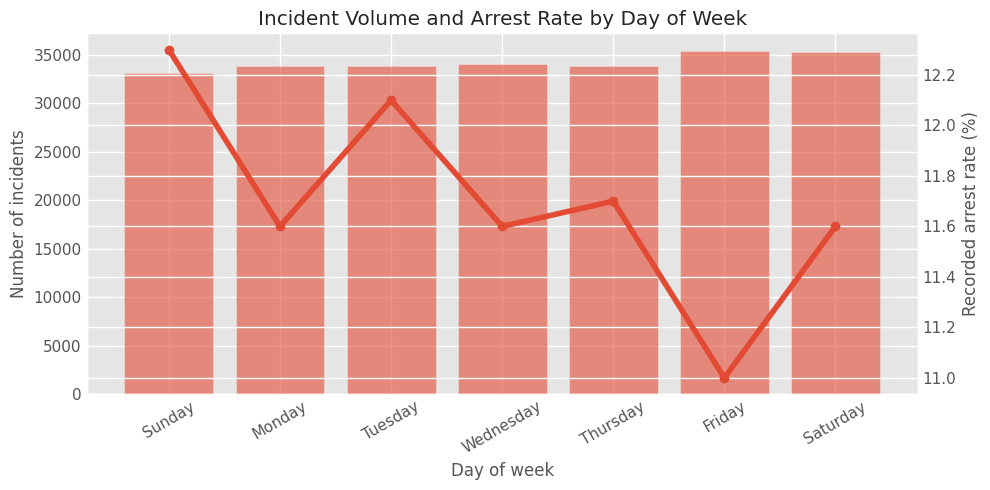

In [0]:
day_labels = {
    1: "Sunday",
    2: "Monday",
    3: "Tuesday",
    4: "Wednesday",
    5: "Thursday",
    6: "Friday",
    7: "Saturday"
}

by_day = (
    temporal_df.groupBy("day_of_week")
    .agg(
        F.count("*").alias("n"),
        F.round(
            100 * F.avg(F.col("Arrest").cast("int")), 1
        ).alias("arrest_rate_pct")
    )
    .orderBy("day_of_week")
    .toPandas()
)

by_day["day_name"] = by_day["day_of_week"].map(day_labels)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(by_day["day_name"], by_day["n"], alpha=0.6)
ax1.set_ylabel("Number of incidents")
ax1.set_xlabel("Day of week")
ax1.tick_params(axis="x", rotation=30)

ax2 = ax1.twinx()
ax2.plot(
    by_day["day_name"],
    by_day["arrest_rate_pct"],
    marker="o"
)
ax2.set_ylabel("Recorded arrest rate (%)")

plt.title("Incident Volume and Arrest Rate by Day of Week")
fig.tight_layout()
plt.show()

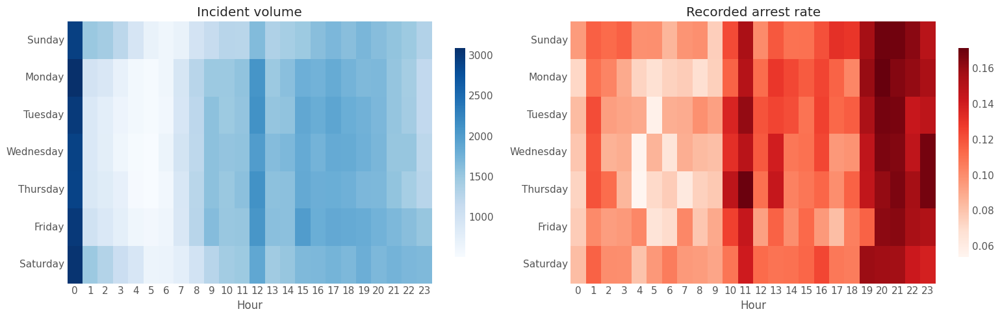

In [0]:
hm = (temporal_df.groupBy("day_of_week", "hour")
      .agg(F.count("*").alias("n"), F.avg(F.col("Arrest").cast("int")).alias("rate")).toPandas())
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, val, title, cmap in [(axes[0], "n", "Incident volume", "Blues"), (axes[1], "rate", "Recorded arrest rate", "Reds")]:
    piv = hm.pivot(index="day_of_week", columns="hour", values=val).rename(index=day_labels)
    sns.heatmap(piv, cmap=cmap, ax=ax, cbar_kws={"shrink": .8}); ax.set_title(title)
    ax.set_xlabel("Hour"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

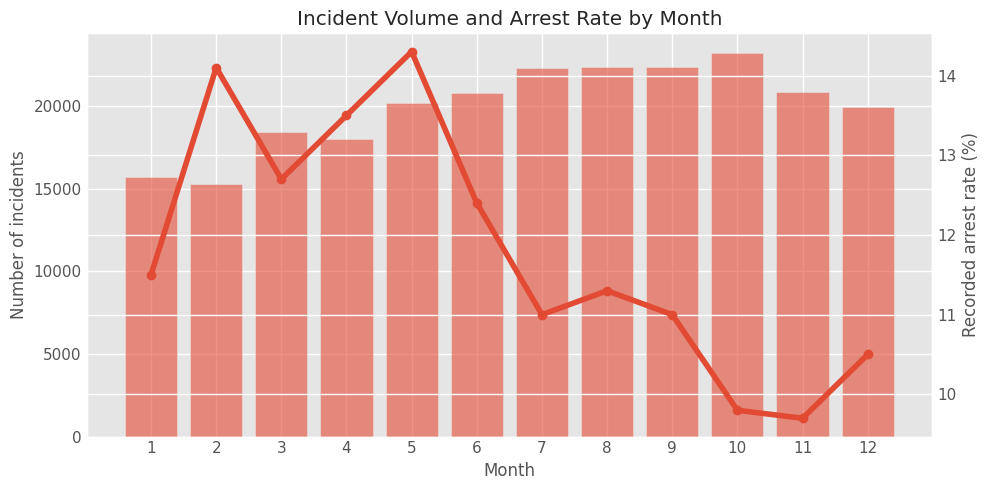

In [0]:
by_month = (
    temporal_df.groupBy("month")
    .agg(
        F.count("*").alias("n"),
        F.round(
            100 * F.avg(F.col("Arrest").cast("int")), 1
        ).alias("arrest_rate_pct")
    )
    .orderBy("month")
    .toPandas()
)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(by_month["month"], by_month["n"], alpha=0.6)
ax1.set_xlabel("Month")
ax1.set_ylabel("Number of incidents")
ax1.set_xticks(range(1, 13))

ax2 = ax1.twinx()
ax2.plot(
    by_month["month"],
    by_month["arrest_rate_pct"],
    marker="o"
)
ax2.set_ylabel("Recorded arrest rate (%)")

plt.title("Incident Volume and Arrest Rate by Month")
fig.tight_layout()
plt.show()

**Time patterns.**
- *Hour:* the arrest rate is lowest in the early morning (7.9–8.1% between 4:00 and 6:00) and highest in the evening (14.8–16.5% between 19:00 and 23:00). 11:00 is also high (15.3%).
- *Midnight:* hour 0 has 20,874 incidents against 7,630 at hour 1. This suggests that many timestamps default to 00:00 when the real time is unknown, so it should not be read as a real peak.
- *Day of week:* almost flat (11.0% on Friday to 12.3% on Sunday), so the weekday is a weak signal.
- *Month:* the rate is highest in May (14.3%) and lowest in October–November (9.7–9.8%), and declines through the year.

In [0]:
by_district = (
    df.groupBy("District")
    .agg(
        F.count("*").alias("n"),
        F.sum(F.col("Arrest").cast("int")).alias("arrests"),
        F.round(
            100 * F.avg(F.col("Arrest").cast("int")), 1
        ).alias("arrest_rate_pct")
    )
    .orderBy(F.desc("arrest_rate_pct"))
)

display(by_district)

District,n,arrests,arrest_rate_pct
31,15,9,60.0
11,13513,3129,23.2
10,10002,1708,17.1
15,8320,1281,15.4
16,9261,1259,13.6
25,11988,1558,13.0
5,9817,1275,13.0
1,13087,1659,12.7
7,10338,1235,11.9
18,12470,1473,11.8


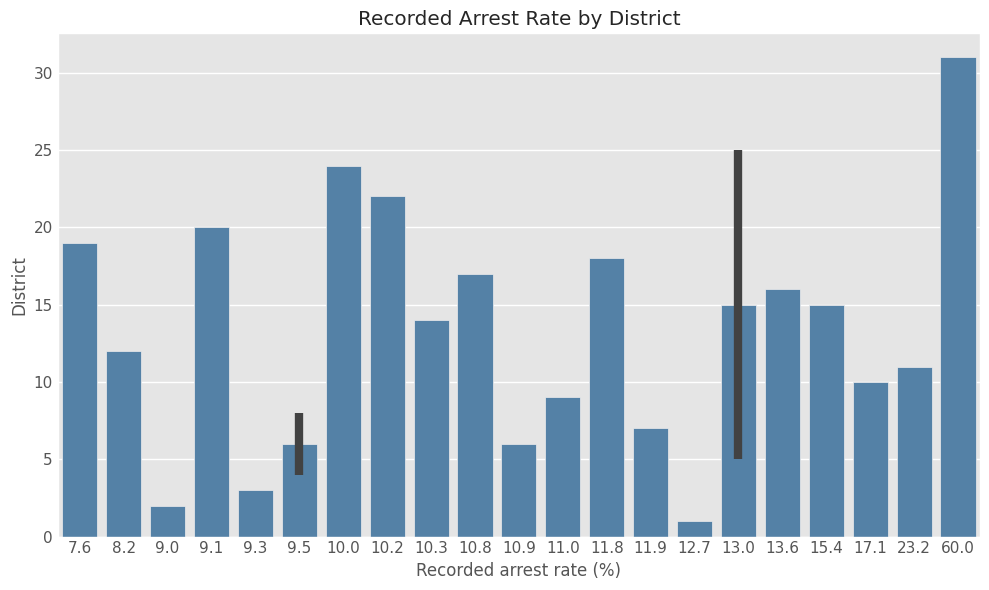

In [0]:
district_pd = by_district.toPandas()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=district_pd,
    x="arrest_rate_pct",
    y="District",
    color="steelblue"
)
plt.title("Recorded Arrest Rate by District")
plt.xlabel("Recorded arrest rate (%)")
plt.ylabel("District")
plt.tight_layout()
plt.show()

In [0]:
type_rate = df.groupBy("Primary Type").agg(F.avg(F.col("Arrest").cast("int")).alias("type_rate"))
dist_gap = (df.join(type_rate, "Primary Type").groupBy("District")
    .agg(F.count("*").alias("n"), F.sum(F.col("Arrest").cast("int")).alias("observed"),
         F.sum("type_rate").alias("expected"))
    .filter("n >= 1000")
    .withColumn("obs_vs_exp", F.round(F.col("observed") / F.col("expected"), 2))
    .orderBy(F.desc("obs_vs_exp")))
display(dist_gap)

District,n,observed,expected,obs_vs_exp
1,13087,1659,1185.4864015668138,1.4
18,12470,1473,1157.915447663686,1.27
14,8177,842,726.6067003165817,1.16
16,9261,1259,1082.6121518728592,1.16
24,8487,848,762.9261005418786,1.11
10,10002,1708,1560.1345393396643,1.09
20,4976,454,422.8361702952324,1.07
25,11988,1558,1464.6960714086385,1.06
17,7009,756,714.5851749211159,1.06
15,8320,1281,1233.6331420008219,1.04


**Districts** 

Raw arrest rates range from 7.6% (district 19) to 23.2% (district 11), a 3× gap. But districts have different crime mixes. Comparing *observed* arrests with the arrests *expected* from the citywide rate of each crime type, the ratio ranges from 0.80 (district 3) to 1.40 (district 1), with district 18 at 1.27. A large part of the raw gap is therefore case mix (for example, more narcotics and weapons incidents), not district performance. This is why district comparisons must be adjusted before any operational use.

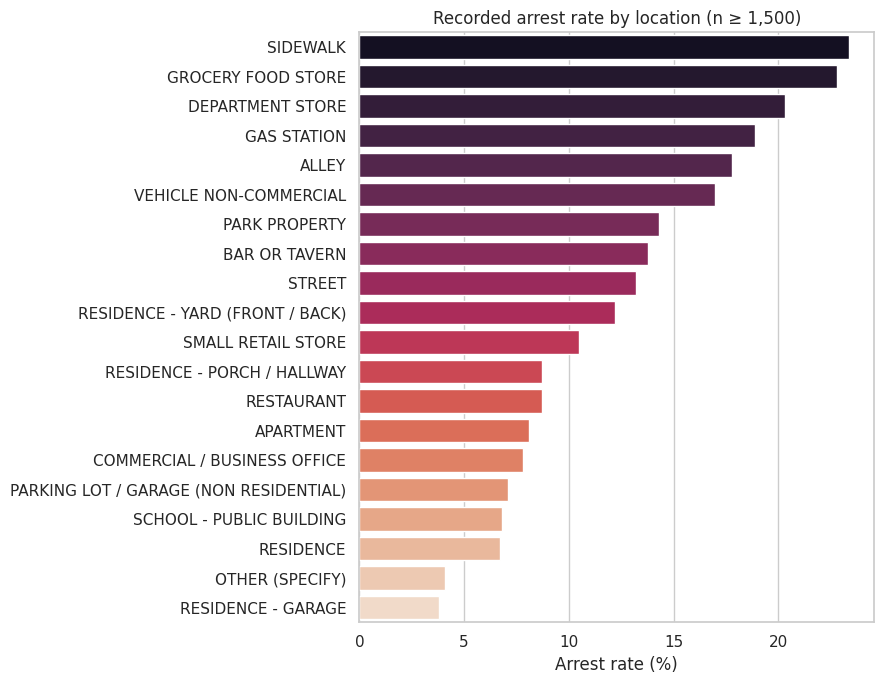

In [0]:
loc = (df.groupBy("Location Description")
       .agg(F.count("*").alias("n"), F.round(100 * F.avg(F.col("Arrest").cast("int")), 1).alias("rate"))
       .filter("n >= 1500").orderBy(F.desc("rate")).toPandas())
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=loc, x="rate", y="Location Description", hue="Location Description", palette="rocket", legend=False, ax=ax)
ax.set_title("Recorded arrest rate by location (n ≥ 1,500)"); ax.set_xlabel("Arrest rate (%)"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Location.** 

Public or commercial settings have the highest rates: sidewalk 23.4% (n = 12,059), grocery store 22.8%, department store 20.3%, gas station 18.9%. Private settings are lowest: residence 6.7%, apartment 8.1%, residential garage 3.8%. This is consistent with arrests being more likely where a suspect is present on scene, but the data cannot confirm that mechanism.

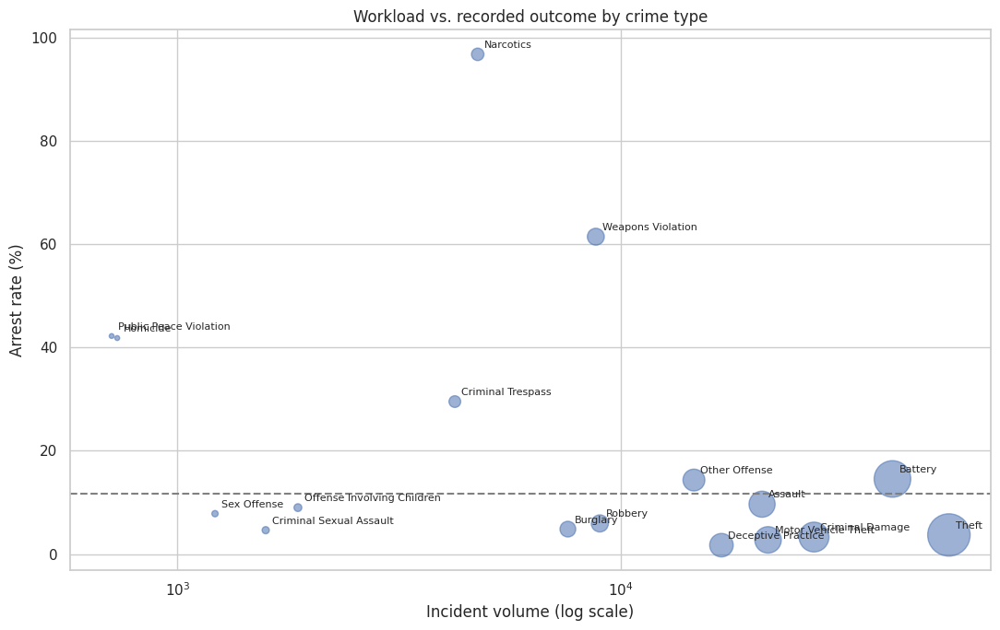

In [0]:
tp = (df.groupBy("Primary Type").agg(F.count("*").alias("n"), (100 * F.avg(F.col("Arrest").cast("int"))).alias("rate"))
        .filter("n >= 500").toPandas())
city = 100 * df.agg(F.avg(F.col("Arrest").cast("int"))).first()[0]
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(tp["n"], tp["rate"], s=tp["n"] / 50, alpha=.55)
for _, r in tp.iterrows():
    ax.annotate(r["Primary Type"].title(), (r["n"], r["rate"]), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.axhline(city, ls="--", color="grey"); ax.set_xscale("log")
ax.set_xlabel("Incident volume (log scale)"); ax.set_ylabel("Arrest rate (%)")
ax.set_title("Workload vs. recorded outcome by crime type")
plt.tight_layout()
plt.show()

In [0]:
by_domestic = (
    df.groupBy("Domestic")
    .agg(
        F.count("*").alias("n"),
        F.sum(F.col("Arrest").cast("int")).alias("arrests"),
        F.round(
            100 * F.avg(F.col("Arrest").cast("int")), 1
        ).alias("arrest_rate_pct")
    )
    .orderBy("Domestic")
)

display(by_domestic)

Domestic,n,arrests,arrest_rate_pct
false,194632,22398,11.5
true,44916,5652,12.6


In [0]:
g = {r["Domestic"]: (r["n"], r["arrests"]) for r in by_domestic.collect()}
(n1, k1), (n2, k2) = g[False], g[True]
p1, p2, pp = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
z = (p2 - p1) / math.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
print(f"Non-domestic {p1:.2%} vs domestic {p2:.2%} | z = {z:.1f} | p = {math.erfc(abs(z) / math.sqrt(2)):.1e}")

Non-domestic 11.51% vs domestic 12.58% | z = 6.4 | p = 1.7e-10


**Domestic context.** 

The arrest rate is 12.6% for domestic incidents (n = 44,916) against 11.5% otherwise (n = 194,632). With this sample size the difference is statistically significant (z ≈ 6.4), but the gap is only 1.1 points, so Domestic is a weak signal on its own.

### 3.3 Spark SQL analysis

In [0]:
df.createOrReplaceTempView("crimes")

sql_by_type = spark.sql("""
    SELECT
        `Primary Type` AS crime_type,
        COUNT(*) AS n,
        SUM(CASE WHEN Arrest = true THEN 1 ELSE 0 END) AS arrests,
        ROUND(
            100.0 * AVG(CASE WHEN Arrest = true THEN 1.0 ELSE 0.0 END),
            1
        ) AS arrest_rate_pct
    FROM crimes
    GROUP BY `Primary Type`
    HAVING COUNT(*) > 1000
    ORDER BY arrest_rate_pct DESC
""")

display(sql_by_type)

crime_type,n,arrests,arrest_rate_pct
NARCOTICS,4755,4599,96.7
WEAPONS VIOLATION,8779,5392,61.4
CRIMINAL TRESPASS,4223,1246,29.5
BATTERY,40945,5951,14.5
OTHER OFFENSE,14609,2092,14.3
ASSAULT,20808,2007,9.6
OFFENSE INVOLVING CHILDREN,1870,168,9.0
SEX OFFENSE,1216,95,7.8
ROBBERY,8963,531,5.9
BURGLARY,7593,366,4.8


### 3.4 Proactive vs reactive offences

In [0]:
PROACTIVE = ["NARCOTICS", "WEAPONS VIOLATION", "CRIMINAL TRESPASS"]
grp = (df.withColumn("group", F.when(F.col("Primary Type").isin(PROACTIVE), "Proactive-type").otherwise("Other (reactive)"))
         .groupBy("group").agg(F.count("*").alias("incidents"), F.sum(F.col("Arrest").cast("int")).alias("arrests"))
         .withColumn("arrest_rate_pct", F.round(100 * F.col("arrests") / F.col("incidents"), 1)))
display(grp)

group,incidents,arrests,arrest_rate_pct
Other (reactive),221791,16813,7.6
Proactive-type,17757,11237,63.3


**Proactive-type offences** 

Narcotics, Weapons Violation and Criminal Trespass are only **7.4% of incidents but 40.1% of all arrests**. These offences are frequently *detected through* the arrest itself, so "predicting an arrest" for them is close to circular. For all other crimes (victim-reported), the arrest rate is only **7.6%**. In the modeling section we therefore report performance separately for the two groups.

### Key EDA takeaways
1. Crime type dominates: three types drive 40% of arrests, while four property crimes are 50% of incidents with a 3.2% arrest rate.
2. Evening hours and public/commercial places have the highest arrest rates; weekday matters little.
3. The raw 3× district gap shrinks to 0.80–1.40 after adjusting for crime mix.
4. Statistical significance is not practical significance (Domestic: z ≈ 6.4, but only +1.1 points).

## 4. Feature Engineering and Model Preparation


### Feature Selection Strategy

The target variable is `Arrest`, a binary indicator of whether an arrest was recorded for an incident.

Administrative identifiers (`ID`) and columns that duplicate other information (`IUCR`, `FBI Code`, `Community Area`) are excluded. The timestamp is split into a date (`Date_`) and a time (`Time`), which are encoded as categories like the other variables. They have many distinct values, so their real usefulness is checked later by comparison with a simple baseline.

Crime descriptions and location fields may carry useful information, but they can also reflect historical policing practices. The model should therefore be read as predicting *recorded historical outcomes*, not the intrinsic probability that an offence can be solved.

In [0]:
work_df = work_df.withColumn("Date_", F.date_format("date", "yyyy-MM-dd")).withColumn("Time", F.date_format("date", "HH:mm:ss"))
work_df = work_df.drop("date")
work_df.display()

ID,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,Date_,Time
12592454,S MORGAN ST,2826,OTHER OFFENSE,HARASSMENT BY ELECTRONIC MEANS,RESIDENCE,false,true,724,7,16,68,26,2022-01-14,15:55:00
12785595,S UNIVERSITY AVE,1544,SEX OFFENSE,SEXUAL EXPLOITATION OF A CHILD,APARTMENT,true,false,324,3,5,69,17,2022-08-05,21:00:00
12808281,W ARDMORE AVE,1562,SEX OFFENSE,AGGRAVATED CRIMINAL SEXUAL ABUSE,RESIDENCE,false,false,1621,16,39,11,17,2022-08-14,14:00:00
12888104,S MAY ST,1477,WEAPONS VIOLATION,RECKLESS FIREARM DISCHARGE,STREET,false,false,733,7,17,68,15,2022-11-10,03:47:00
13209277,W JACKSON BLVD,810,THEFT,OVER $500,COMMERCIAL / BUSINESS OFFICE,false,false,113,1,4,32,6,2022-08-15,09:00:00
12622465,N FRANCISCO AVE,486,BATTERY,DOMESTIC BATTERY SIMPLE,HOSPITAL BUILDING / GROUNDS,true,true,1211,12,26,24,08B,2022-02-19,10:36:00
12640859,W PRATT BLVD,486,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,true,true,2431,24,49,1,08B,2022-03-13,05:15:00
12667337,N CHERRY AVE,4387,OTHER OFFENSE,VIOLATE ORDER OF PROTECTION,WAREHOUSE,true,true,1822,18,27,8,26,2022-04-10,21:38:00
12671049,E OHIO ST,486,BATTERY,DOMESTIC BATTERY SIMPLE,VEHICLE - COMMERCIAL,true,true,1834,18,2,8,08B,2022-04-14,22:10:00
12678035,N BROADWAY,810,THEFT,OVER $500,APARTMENT,true,true,1914,19,46,3,6,2022-04-22,23:30:00


In [0]:
work_df.printSchema()

root
 |-- ID: long (nullable = true)
 |-- Block: string (nullable = true)
 |-- IUCR: string (nullable = true)
 |-- Primary Type: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Location Description: string (nullable = false)
 |-- Arrest: boolean (nullable = true)
 |-- Domestic: boolean (nullable = true)
 |-- Beat: long (nullable = true)
 |-- District: long (nullable = true)
 |-- Ward: long (nullable = true)
 |-- Community Area: long (nullable = true)
 |-- FBI Code: string (nullable = true)
 |-- Date_: string (nullable = true)
 |-- Time: string (nullable = true)



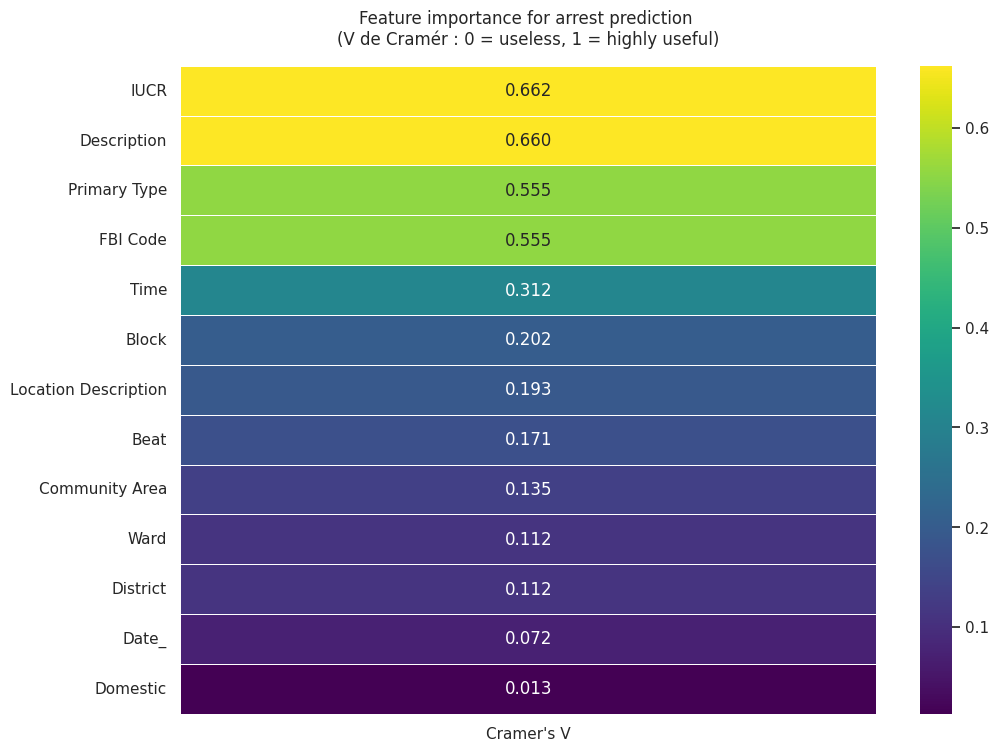

In [0]:
import pyspark.sql.functions as F
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.stat import ChiSquareTest
from pyspark.ml import Pipeline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


cols_to_test = [
    "IUCR", "Block","Primary Type", "Description", "Location Description",
    "Domestic", "Beat", "District", "Ward", "Community Area", 
    "FBI Code", "Date_", "Time"]


temp_df = work_df.withColumn("Arrest_num", F.col("Arrest").cast("integer"))

indexers = []
vector_inputs = []

for col in cols_to_test:
    out_col = f"{col}_idx"
    vector_inputs.append(out_col)
    temp_df = temp_df.withColumn(f"{col}_str", F.col(col).cast("string"))
    indexer = StringIndexer(inputCol=f"{col}_str", outputCol=out_col, handleInvalid="keep")
    indexers.append(indexer)


pipeline = Pipeline(stages=indexers)
encoded_df = pipeline.fit(temp_df).transform(temp_df)


assembler = VectorAssembler(inputCols=vector_inputs, outputCol="cat_features")
vec_df = assembler.transform(encoded_df)


chi_results = ChiSquareTest.test(vec_df, "cat_features", "Arrest_num").head()

# Cramer's V : V = sqrt( Chi2 / N )
# (Doable because Arrest is boolean)
n = vec_df.count()
chi_sq_values = chi_results.statistics.toArray()
cramer_v_values = np.sqrt(chi_sq_values / n)


cramer_pd = pd.DataFrame({
    "Cramer's V": cramer_v_values
}, index=cols_to_test).sort_values(by="Cramer's V", ascending=False)

plt.figure(figsize=(10, 8))
sns.heatmap(cramer_pd, annot=True, cmap='viridis', fmt='.3f', linewidths=0.5)
plt.title("Feature importance for arrest prediction \n(V de Cramér : 0 = useless, 1 = highly useful)", pad=15)

display(plt.gcf())
plt.close()

Based on the graph above and the exploration, we keep the following variables:

- **Strongly associated with the arrest:** Description, Primary Type, Location Description, Block, Beat, Ward, District, and the time information (`Date_` and `Time`).
- **Kept despite a weak association:** Domestic. It has the lowest Cramér's V, but we expect it to matter more in combination with other variables.

`ID`, `IUCR`, `FBI Code` and `Community Area` are removed as identifiers or duplicates.

Typically, SMOTE is used to address a strong class imbalance (88.3% no arrest / 11.7% arrest). It is not available in Spark MLlib, and creating synthetic points by interpolating between *encoded categories* would not make sense.

We therefore use **class weighting**: each class is weighted inversely to its frequency, so that misclassifying an arrest costs more than misclassifying a non-arrest. This prevents the models from reaching a high accuracy by always predicting the majority class, and forces them to learn the patterns that distinguish arrests.

In [0]:
final_df = work_df
global_df = final_df.drop('ID','IUCR','FBI Code','Community Area')
X = final_df.drop('ID','IUCR','FBI Code','Community Area','Arrest')
y = final_df.select("Arrest")
X.display()


Block,Primary Type,Description,Location Description,Domestic,Beat,District,Ward,Date_,Time
S MORGAN ST,OTHER OFFENSE,HARASSMENT BY ELECTRONIC MEANS,RESIDENCE,true,724,7,16,2022-01-14,15:55:00
S UNIVERSITY AVE,SEX OFFENSE,SEXUAL EXPLOITATION OF A CHILD,APARTMENT,false,324,3,5,2022-08-05,21:00:00
W ARDMORE AVE,SEX OFFENSE,AGGRAVATED CRIMINAL SEXUAL ABUSE,RESIDENCE,false,1621,16,39,2022-08-14,14:00:00
S MAY ST,WEAPONS VIOLATION,RECKLESS FIREARM DISCHARGE,STREET,false,733,7,17,2022-11-10,03:47:00
W JACKSON BLVD,THEFT,OVER $500,COMMERCIAL / BUSINESS OFFICE,false,113,1,4,2022-08-15,09:00:00
N FRANCISCO AVE,BATTERY,DOMESTIC BATTERY SIMPLE,HOSPITAL BUILDING / GROUNDS,true,1211,12,26,2022-02-19,10:36:00
W PRATT BLVD,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,true,2431,24,49,2022-03-13,05:15:00
N CHERRY AVE,OTHER OFFENSE,VIOLATE ORDER OF PROTECTION,WAREHOUSE,true,1822,18,27,2022-04-10,21:38:00
E OHIO ST,BATTERY,DOMESTIC BATTERY SIMPLE,VEHICLE - COMMERCIAL,true,1834,18,2,2022-04-14,22:10:00
N BROADWAY,THEFT,OVER $500,APARTMENT,true,1914,19,46,2022-04-22,23:30:00


In [0]:
features_cols = X.columns
ml_df = global_df.withColumn("label", F.col("Arrest").cast("integer")).drop("Arrest")
ml_df.display()

Block,Primary Type,Description,Location Description,Domestic,Beat,District,Ward,Date_,Time,label
S MORGAN ST,OTHER OFFENSE,HARASSMENT BY ELECTRONIC MEANS,RESIDENCE,true,724,7,16,2022-01-14,15:55:00,0
S UNIVERSITY AVE,SEX OFFENSE,SEXUAL EXPLOITATION OF A CHILD,APARTMENT,false,324,3,5,2022-08-05,21:00:00,1
W ARDMORE AVE,SEX OFFENSE,AGGRAVATED CRIMINAL SEXUAL ABUSE,RESIDENCE,false,1621,16,39,2022-08-14,14:00:00,0
S MAY ST,WEAPONS VIOLATION,RECKLESS FIREARM DISCHARGE,STREET,false,733,7,17,2022-11-10,03:47:00,0
W JACKSON BLVD,THEFT,OVER $500,COMMERCIAL / BUSINESS OFFICE,false,113,1,4,2022-08-15,09:00:00,0
N FRANCISCO AVE,BATTERY,DOMESTIC BATTERY SIMPLE,HOSPITAL BUILDING / GROUNDS,true,1211,12,26,2022-02-19,10:36:00,1
W PRATT BLVD,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,true,2431,24,49,2022-03-13,05:15:00,1
N CHERRY AVE,OTHER OFFENSE,VIOLATE ORDER OF PROTECTION,WAREHOUSE,true,1822,18,27,2022-04-10,21:38:00,1
E OHIO ST,BATTERY,DOMESTIC BATTERY SIMPLE,VEHICLE - COMMERCIAL,true,1834,18,2,2022-04-14,22:10:00,1
N BROADWAY,THEFT,OVER $500,APARTMENT,true,1914,19,46,2022-04-22,23:30:00,1


In [0]:
#encoding
for col in features_cols:
    ml_df = ml_df.withColumn(f"{col}_str", F.col(col).cast("string"))

indexers = [
    StringIndexer(inputCol=f"{col}_str", outputCol=f"{col}_idx", handleInvalid="keep")
    for col in features_cols
]

#vectorizing
assembler = VectorAssembler(
    inputCols=[f"{col}_idx" for col in features_cols],
    outputCol="features"
)

pipeline = Pipeline(stages=indexers + [assembler])
ml_df_encoded = pipeline.fit(ml_df).transform(ml_df)

#Calculation of the weights
total = ml_df_encoded.count()
count_0 = ml_df_encoded.filter(F.col("label") == 0).count()
count_1 = ml_df_encoded.filter(F.col("label") == 1).count()

#Weights application
ml_df_weighted = ml_df_encoded.withColumn(
    "weight",
    F.when(F.col("label") == 1, total / (2 * count_1)).otherwise(total / (2 * count_0))
)

train_data, test_data = ml_df_weighted.randomSplit([0.7, 0.3], seed=42)

Training the models
Undergoing training : Decision Tree...
Undergoing training : Random Forest...
Undergoing training : Gradient Boosting (GBT)...


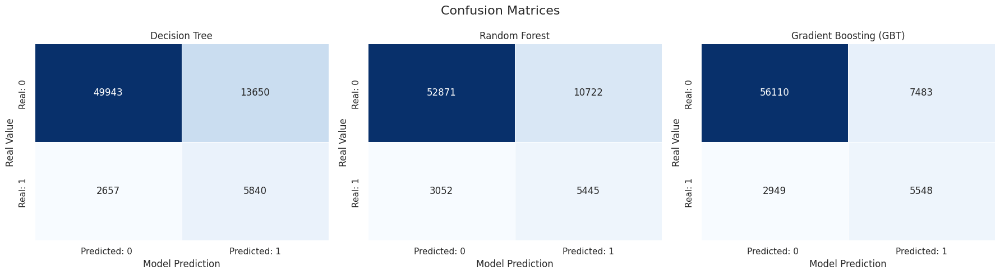

Model,Accuracy,F1-Score,Precision,Recall,AUC-ROC
Gradient Boosting (GBT),0.8553,0.8679,0.8883,0.8553,0.8443
Random Forest,0.8089,0.8325,0.8737,0.8089,0.8308
Decision Tree,0.7738,0.8075,0.8729,0.7738,0.7136


In [0]:
dt = DecisionTreeClassifier(featuresCol="features", labelCol="label", weightCol="weight", seed= 42,maxBins=3000)
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="weight", seed=42,maxBins=3000)
gbt = GBTClassifier(featuresCol="features", labelCol="label", weightCol="weight", seed=42,maxBins=3000) #spark native alternative for XGBoost

modeles = {
    "Decision Tree": dt, 
    "Random Forest": rf, 
    "Gradient Boosting (GBT)": gbt
}

#Performance metrics
eval_f1 = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
eval_acc = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
eval_prec = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedPrecision")
eval_rec = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedRecall")
eval_auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

results = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Confusion Matrices", fontsize=16)
print("Training the models")

for i, (nom, algorithme) in enumerate(modeles.items()):
    print(f"Undergoing training : {nom}...")
    model = algorithme.fit(train_data)
    predictions = model.transform(test_data)
    results.append({
        "Model": nom,
        "Accuracy": round(eval_acc.evaluate(predictions), 4),
        "F1-Score": round(eval_f1.evaluate(predictions), 4),
        "Precision": round(eval_prec.evaluate(predictions), 4),
        "Recall": round(eval_rec.evaluate(predictions), 4),
        "AUC-ROC": round(eval_auc.evaluate(predictions), 4)
    })
    cm_spark = predictions.groupBy("label", "prediction").count().toPandas()
    cm = pd.DataFrame([[0, 0], [0, 0]], index=["Real: 0 ", "Real: 1 "], columns=["Predicted: 0 ", "Predicted: 1"])
    for _, row in cm_spark.iterrows():
        r = int(row['label'])
        c = int(row['prediction'])
        cm.iloc[r, c] = int(row['count'])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i], cbar=False, linewidths=0.5)
    axes[i].set_title(nom)
    axes[i].set_ylabel("Real Value")
    axes[i].set_xlabel("Model Prediction")
plt.tight_layout()
display(plt.gcf())
plt.close()

df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by="F1-Score", ascending=False)
display(df_results)

### What the first comparison tells us

**Gradient Boosting comes out on top.** It leads on every metric (AUC-ROC 0.844, F1 0.868), ahead of the Random Forest (0.831 / 0.833) and the Decision Tree (0.714 / 0.808). Going from one tree to an ensemble is what makes the real difference; boosting then adds a smaller, steady improvement.

**The models find about the same arrests, but not the same number of false alarms.** All three catch roughly two thirds of the arrests (65% for GBT). The gap is in the false alarms: GBT raises 7,483, against 10,722 for the Random Forest and 13,650 for the Decision Tree. In practice, GBT produces about 1.4 false alarms for each arrest found, versus about 2.3 for the Decision Tree. It is the model that wastes the least of a reviewer's time.

**The headline metrics flatter the results.** Because they are weighted, "Recall" simply repeats "Accuracy" and "Precision" mostly reflects the majority class (88% of incidents have no arrest). On the arrest class itself, GBT reaches a precision of about 0.43, a recall of about 0.65 and an F1 of about 0.52.

**Accuracy is not the right yardstick here.** A model that always answers "no arrest" would be right 88.2% of the time, more than GBT's 85.5%. That is the price of class weighting: we accept a few more mistakes on the majority class in order to actually detect arrests.

**What we cannot conclude yet.** These scores come from a single random split, with default settings and nothing to compare them to. The next step is to check whether the models really beat a simple rule based on past arrest rates.

### Complementary analyses: per-class metrics, baseline and business lift

The comparison above uses *weighted* metrics (weighted recall equals accuracy). This section completes it with (i) metrics on the **arrest class**, (ii) a **simple baseline** to test whether machine learning adds value, (iii) a **lift analysis** that translates the model into workload terms, and (iv) robustness checks.

In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator as MCE, BinaryClassificationEvaluator as BCE
from pyspark.ml.functions import vector_to_array

def arrest_class_metrics(pred, name, raw="rawPrediction"):
    m = lambda metric: MCE(labelCol="label", predictionCol="prediction", metricName=metric, metricLabel=1.0).evaluate(pred)
    b = lambda metric: BCE(labelCol="label", rawPredictionCol=raw, metricName=metric).evaluate(pred)
    return {"Model": name, "Precision (arrest)": m("precisionByLabel"), "Recall (arrest)": m("recallByLabel"),
            "F1 (arrest)": m("fMeasureByLabel"), "AUC-ROC": b("areaUnderROC"), "AUC-PR": b("areaUnderPR")}

fitted_all, preds_all, rows = {}, {}, []
for name, algo in modeles.items():
    fitted_all[name] = algo.fit(train_data)
    preds_all[name] = fitted_all[name].transform(test_data)
    rows.append(arrest_class_metrics(preds_all[name], name))

display(pd.DataFrame(rows).round(4).sort_values("F1 (arrest)", ascending=False))

Model,Precision (arrest),Recall (arrest),F1 (arrest),AUC-ROC,AUC-PR
Gradient Boosting (GBT),0.4258,0.6529,0.5154,0.8443,0.6346
Random Forest,0.3368,0.6408,0.4415,0.8308,0.5665
Decision Tree,0.2996,0.6873,0.4173,0.7136,0.4993


**Reading the table** 

On the arrest class, the best model (Gradient Boosting) reaches a precision of about 0.43 and a recall of about 0.65 (F1 ≈ 0.52), computed from its confusion matrix (5,548 arrests detected out of 8,497; 7,483 false alarms). Weighted precision (0.89) and accuracy (0.86) look much better only because 88% of incidents have no arrest. The arrest-class metrics are the ones that matter for a business use.

In [0]:
M = 10                                           # smoothing strength
n_train = train_data.count()
prior = train_data.filter("label = 1").count() / n_train

lookup = (train_data.groupBy("Primary Type", "Description")
          .agg(F.sum("label").alias("k"), F.count("*").alias("n"))
          .withColumn("score", (F.col("k") + M * prior) / (F.col("n") + M))
          .select("Primary Type", "Description", "score"))

base_pred = (test_data.join(lookup, ["Primary Type", "Description"], "left")
             .fillna({"score": prior}))

res_base = {"Model": "Baseline: lookup (Primary Type × Description)", "Precision (arrest)": None,
            "Recall (arrest)": None, "F1 (arrest)": None,
            "AUC-ROC": BCE(labelCol="label", rawPredictionCol="score", metricName="areaUnderROC").evaluate(base_pred),
            "AUC-PR": BCE(labelCol="label", rawPredictionCol="score", metricName="areaUnderPR").evaluate(base_pred)}

display(pd.DataFrame(rows + [res_base]).round(4).sort_values("AUC-PR", ascending=False))

Model,Precision (arrest),Recall (arrest),F1 (arrest),AUC-ROC,AUC-PR
Baseline: lookup (Primary Type × Description),null,null,null,0.8847,0.678
Gradient Boosting (GBT),0.4258,0.6529,0.5154,0.8443,0.6346
Random Forest,0.3368,0.6408,0.4415,0.8308,0.5665
Decision Tree,0.2996,0.6873,0.4173,0.7136,0.4993


**A simple rule beats the models.** 

Without any machine learning, the baseline (the historical arrest rate of each crime type and description) reaches an AUC-ROC of 0.885 and an AUC-PR of 0.678. The best MLlib model, Gradient Boosting, gets 0.844 and 0.635. Knowing *what* the offence is explains almost everything the models can predict, and the extra information they receive (street, beat, ward, date, time) does not seem to help; it may even add noise.

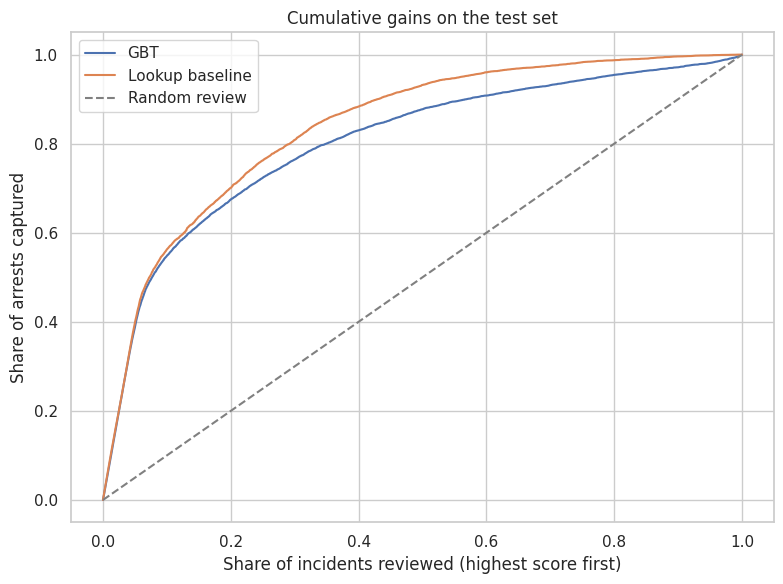

Model,Top 10% reviewed,Top 20% reviewed,Top 30% reviewed
GBT,55% of arrests,67% of arrests,76% of arrests
Lookup baseline,56% of arrests,70% of arrests,81% of arrests


In [0]:
best_name = "Gradient Boosting (GBT)"
scored = preds_all[best_name].select("label", vector_to_array("probability")[1].alias("p")).toPandas()
base_scored = base_pred.select("label", F.col("score").alias("p")).toPandas()   # only the scored test set (≈72k rows)

def gains(d):
    y = d.sort_values("p", ascending=False)["label"].to_numpy()
    return np.arange(1, len(y) + 1) / len(y), np.cumsum(y) / y.sum()

fig, ax = plt.subplots(figsize=(8, 6))
table = []
for name, d in [("GBT", scored), ("Lookup baseline", base_scored)]:
    x, g = gains(d)
    ax.plot(x, g, label=name)
    table.append({"Model": name, **{f"Top {int(q*100)}% reviewed": f"{np.interp(q, x, g):.0%} of arrests" for q in (0.1, 0.2, 0.3)}})
ax.plot([0, 1], [0, 1], "--", color="grey", label="Random review")
ax.set_xlabel("Share of incidents reviewed (highest score first)")
ax.set_ylabel("Share of arrests captured")
ax.set_title("Cumulative gains on the test set")
ax.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame(table))

**What it means for a reviewer** 

The two curves are almost identical for the first 10% of incidents, then the baseline pulls ahead. Reviewing the 20% of incidents with the highest score captures 70% of arrests with the baseline and 67% with GBT; at 30%, it is 81% against 76%. Either way, a prioritised review is far more efficient than a random one (20% of incidents would capture only 20% of arrests).

In [0]:
PROACTIVE = ["NARCOTICS", "WEAPONS VIOLATION", "CRIMINAL TRESPASS"]
out = []
for grp, cond in [("Proactive-type (narcotics, weapons, trespass)", F.col("Primary Type").isin(PROACTIVE)),
                  ("All other crimes (reactive)", ~F.col("Primary Type").isin(PROACTIVE))]:
    g, b = preds_all[best_name].filter(cond), base_pred.filter(cond)
    out.append({"Group": grp, "Test incidents": g.count(), "Arrest rate": round(g.agg(F.avg("label")).first()[0], 3),
                "GBT AUC-ROC": round(BCE(labelCol="label", rawPredictionCol="rawPrediction").evaluate(g), 3),
                "Baseline AUC-ROC": round(BCE(labelCol="label", rawPredictionCol="score").evaluate(b), 3)})
display(pd.DataFrame(out))

Group,Test incidents,Arrest rate,GBT AUC-ROC,Baseline AUC-ROC
"Proactive-type (narcotics, weapons, trespass)",5383,0.629,0.916,0.928
All other crimes (reactive),66707,0.077,0.763,0.823


**Robustness** 

The score depends heavily on the type of crime. For narcotics, weapons and trespass offences (5,383 test incidents, 63% with an arrest), the arrest is often how the offence is detected in the first place, so both the model and the simple rule do very well (AUC-ROC 0.916 and 0.928). For all other crimes (66,707 incidents, only 7.7% with an arrest), the task is much harder: the model falls to 0.763 and the simple rule to 0.823. The overall score is therefore flattered by the easy cases, and the gap in favour of the simple rule is even wider on victim-reported crimes, where the question of investigative usefulness actually arises.

## 5. Results and Model Comparison

### 5.1 What the data says

- **Crime type is what matters most.** Narcotics (96.7%, n = 4,755), Weapons Violation (61.4%, n = 8,779) and Criminal Trespass (29.5%, n = 4,223) have the highest arrest rates. Deceptive Practice (1.7%), Motor Vehicle Theft (2.7%), Criminal Damage (3.3%) and Theft (3.7%, n = 54,884) have the lowest. These four property crimes are 50.3% of all incidents, but only 3.2% of them lead to an arrest.
- **Time and place matter less.** Arrests are most frequent in the evening (14.8–16.5% between 19:00 and 23:00) and least frequent around 4:00–6:00 (about 8%). The day of the week hardly changes anything (11.0–12.3%). The rate falls through the year, from 14.3% in May to 9.7% in November. The spike at 00:00 mostly comes from default timestamps, not from real midnight crimes.
- **Districts need care.** Raw arrest rates range from 7.6% to 23.2%, but once the crime mix is taken into account the gap shrinks a lot (observed/expected ratio from 0.80 in district 3 to 1.40 in district 1). Raw comparisons between districts are misleading.
- **Domestic incidents** have a slightly higher arrest rate (12.6%, n = 44,916) than the others (11.5%, n = 194,632). The difference is statistically significant (z ≈ 6.4) but small.

### 5.2 How well do the models predict arrests?

All models were evaluated on the same test set: 72,090 incidents, of which 8,497 (11.8%) led to an arrest. Precision, recall and F1 are measured on the arrest class.

| Model | Precision | Recall | F1 | AUC-ROC | AUC-PR |
|---|---|---|---|---|---|
| Baseline: historical rate by crime type × description | n/a | n/a | n/a | **0.885** | **0.678** |
| Gradient Boosting (GBT) | 0.426 | 0.653 | 0.515 | 0.844 | 0.635 |
| Random Forest | 0.337 | 0.641 | 0.442 | 0.831 | 0.567 |
| Decision Tree | 0.300 | 0.687 | 0.417 | 0.714 | 0.499 |

**Among the three MLlib models, Gradient Boosting is the best:** it has the highest AUC and the fewest false alarms. It flags 18.1% of incidents and catches 65% of the arrests, about 3.6 times better than random. Accuracy (85.5%) is not a useful criterion here, since always answering "no arrest" would be right 88.2% of the time.

**But the simple baseline does better than every model.** Without any machine learning, it reaches an AUC-ROC of 0.885 and an AUC-PR of 0.678. The offence itself carries almost all the predictable signal, and the extra variables given to the models (street, beat, ward, date, time) do not bring any gain here.

### 5.3 Using the score to prioritise incidents

| Share of incidents reviewed (highest score first) | Arrests captured, baseline | Arrests captured, GBT |
|---|---|---|
| Top 10% | 56% | 55% |
| Top 20% | 70% | 67% |
| Top 30% | 81% | 76% |

A random review of 20% of incidents would capture only 20% of arrests. Both approaches are far better, and the baseline is slightly ahead from the top 10% onward.

### 5.4 Is the result robust?

| Group | Test incidents | Arrest rate | GBT AUC-ROC | Baseline AUC-ROC |
|---|---|---|---|---|
| Narcotics, weapons, trespass | 5,383 | 62.9% | 0.916 | 0.928 |
| All other crimes (victim-reported) | 66,707 | 7.7% | 0.763 | 0.823 |

The overall score is flattered by the easy cases. For narcotics, weapons and trespass offences, the arrest is often how the offence is detected, so predicting it is almost circular. On all other crimes, which are 93% of incidents, performance drops for both approaches, and the simple rule keeps its lead (0.823 against 0.763).

## 6. Business Implications

### 6.1 Where to look first
Four property crimes (theft, motor vehicle theft, criminal damage, deceptive practice) are 120,447 incidents, half of the total, with an arrest rate of only 3.2% (3,802 arrests). This is where the gap between workload and outcome is largest. As an illustration, one extra point of arrest rate on these crimes would mean about 1,200 more arrests. The data shows the gap but cannot explain it.

### 6.2 Using a score to prioritise incidents
If incidents had to be ranked for review, a simple table of historical arrest rates by crime type and description is enough: reviewing the top 20% of incidents captures 70% of arrests, slightly more than the best model (67%). It is as effective as the models, and it can be explained and audited line by line.

A score never proves that an arrest will or should happen. It must not be used to deny an investigation, to justify coercive action, or to label people as suspicious.

### 6.3 Recommendations
1. Track incident volumes **and** arrest rates together, by crime category.
2. Compare districts with indicators adjusted for crime mix, not raw arrest rates.
3. Prefer a transparent rule to a complex model unless richer data shows a clear gain.
4. Look more closely at time periods and places with high volumes and low arrest rates (for example, early mornings and residential settings).

### 6.4 Conditions for any further use
Before any operational use, the approach would need validation on later periods, a review of data quality, an analysis of differences between areas, and clear human oversight. This project shows what the data can and cannot predict; it does not show that deploying a model would improve public safety.

## 7. Limitations

### Data
- The data covers one city and one year, so the results may not apply to other places or periods.
- The target records whether an arrest is linked to an incident. It does not measure the whole investigation or how solvable a crime is.
- Hour 0 has 20,874 incidents against 7,630 at hour 1, which suggests that many timestamps default to 00:00, limiting what time-of-day variables can tell us.
- Narcotics, weapons and trespass offences are often recorded *because of* the arrest, so the target is partly circular for them.
- Several incidents may belong to the same case, so they are not fully independent.

### Modeling
- The train/test split is random, so incidents from the same period and area can be in both sets. Scores may be slightly optimistic, and we did not test performance on later months.
- Models were trained with default settings and no cross-validation, so a tuned model could perform differently.
- Class weighting changes the learning objective and may distort predicted probabilities.
- Predictive associations do not show causes.
- The exact date and time are encoded as categories with many distinct values, which may add noise rather than information.

### Fairness and responsible use
Geographic variables can reflect past differences in police activity, reporting and enforcement. A high score for a recorded arrest is not evidence that a person is more likely to commit a crime or deserves different treatment. Any real deployment would need independent validation, a fairness audit, human oversight and a legal and ethical review.

## 8. Conclusion

**What we found.** Recorded arrests depend mostly on the type of offence. Narcotics, weapons and trespass offences are only 7.4% of incidents but 40% of arrests, while four property crimes make up half of all incidents and lead to an arrest only 3.2% of the time. Time and place matter much less, and the gaps between districts are largely explained by their crime mix.

**What the models bring.** Gradient Boosting is the best of the three Spark MLlib models: it finds 65% of arrests with a precision of 43%. But a simple table of historical arrest rates by crime type and description does even better (AUC-ROC 0.885 against 0.844) and captures more arrests in the top 20% of incidents (70% against 67%). The gap is clearer on victim-reported crimes (AUC-ROC 0.823 against 0.763), which are 93% of incidents. With the variables available, machine learning adds no value over a transparent rule.

**What it means for decision-makers.**
- Focus on high-volume, low-clearance property crimes, which are half of all incidents.
- Do not compare districts on raw arrest rates; adjust for crime mix first.
- To prioritise incidents, a simple and auditable table is enough. Any model should support human judgement, never replace it.

**Next steps.** Validate on later months, use several years of data, tune the models, and test richer information (evidence, response time, victim and offender context) that this dataset does not contain.